# Etude de la mortalité en Île-de-France

Nous souhaitons lier la pollution à certains indices, comme la mortalité, pour tenter d'observer si corrélation il y a, voire aller plus loin jusqu'à étudier une causalité. 

Pour ce faire, nous récupérons des données sur le nombre de décès par commune en France sur datagouv. Nous allons extraire ces données et les restreindre à l'Île-de-France pour en faire une première analyse. Il est important de noter que la variable géographique liée au décès est le code_commune du décès : c'est à dire l'endroit où la personne est décédée. Ainsi, il n'indique peut être pas correctement le lieu où la personne vivait et était donc soumise à la pollution atmosphérique. C'est un détail à garder en tête pour la suite de notre analyse. 

Afin d'obtenir un indicateur un peu plus performant que simplement le nombre de décès (qui peut être trompeur du fait de l'hétérogénéité de la densité de la population, mais qui ne témoigne également pas de potentiels mouvements de population, d'exode rural ou bien de désertification), nous récupérons également des données sur le nombre d'habitants par commune. Ainsi, nous pourrons calculer un taux de mortalité - imparfait du fait de la limite mentionnée précédemment - qui nous permettra une analyse plus fine. 

In [19]:
# Téléchargement des packages

import pandas as pd
import requests
import io
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns

## Nombre de décès

Nous commençons par télécharger les données sur le nombre de décès à partir de data.gouv.

In [20]:
url_deces = f"https://www.data.gouv.fr/api/1/datasets/r/0b0c0fbc-af9a-4b9d-9949-b171e7e6fe4a"
deces = pd.read_csv(url_deces, sep=';')
deces.head()

,code_lieu_deces,deces_2008,deces_2009,deces_2010,deces_2011,deces_2012,deces_2013,deces_2014,deces_2015,deces_2016,...,deces_2024,deces_2025,total_2008_2025,moy_annuelle,annee_pic,deces_annee_pic,evol_pct_2008_vs_2025,tendance,surplus_covid_2020,surplus_pct_covid_2020
0,31555,4559,4647,4650,4763,4924,4877,4981,5208,5153,...,5433,5626,92323,5129.1,2022,5642,23.4,Forte hausse,-9,-0.2
1,06088,4663,4576,4323,4416,4703,4763,4667,4803,4957,...,4651,4695,85661,4758.9,2021,5253,0.7,Stable,163,3.4
2,59350,4155,4224,4182,4081,4346,4499,4469,4466,4586,...,4334,4436,80527,4473.7,2020,4886,6.8,Hausse,225,4.8
3,33063,4155,4212,4178,4090,4306,4236,4379,4535,4221,...,4142,4108,76144,4230.2,2015,4535,-1.1,Stable,-124,-2.9
4,67482,3717,3743,3765,3753,3893,4188,4045,4213,4016,...,4380,4415,74441,4135.6,2020,4730,18.8,Hausse,619,15.1


In [21]:
deces.info()

<class 'pandas.DataFrame'>
RangeIndex: 36765 entries, 0 to 36764
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   code_lieu_deces         36765 non-null  str    
 1   deces_2008              36765 non-null  int64  
 2   deces_2009              36765 non-null  int64  
 3   deces_2010              36765 non-null  int64  
 4   deces_2011              36765 non-null  int64  
 5   deces_2012              36765 non-null  int64  
 6   deces_2013              36765 non-null  int64  
 7   deces_2014              36765 non-null  int64  
 8   deces_2015              36765 non-null  int64  
 9   deces_2016              36765 non-null  int64  
 10  deces_2017              36765 non-null  int64  
 11  deces_2018              36765 non-null  int64  
 12  deces_2019              36765 non-null  int64  
 13  deces_2020              36765 non-null  int64  
 14  deces_2021              36765 non-null  int64  
 

Nous avons donc bien le code_lieu_deces, qui correspond au code_commune INSEE et est bien en caractère (donc pas de problème pour les communes commençant par 0), ainsi que le nombre de décès au sein de la commune, de l'année 2008 à 2025. Nous pouvons remarquer que les variables contenant le nombre de décès par année ne contiennent aucune valeur manquante à priori. Certaines statistiques descriptives sont déjà calculées, comme le total sur cette période, la moyenne annuelle, l'année pic ou bie, l'évolution entre 2008 et 2025. Une certaine importance est déjà donnée au Covid et à raison : la pandémie a à la fois augmenter le nombre de décès, mais le confinement a pu réduire la pollution atmosphérique ce qui rend l'effet global sur la mortalité ambigu. 

### Île-de-France 

A présent, nous nous concentrons sur les données en Île de France. Pour cela nous allons créer une colonne département à partir de code_lieu_décès qui correspond au code de la commune. Les deux premiers chiffres sont isolés, et nous nous limitons ensuite au département d'Île-de-France. 

In [22]:
deces = deces.rename({"code_lieu_deces": "code_commune"}, axis=1)

deces["dep"] = deces["code_commune"].str[:2]
deces[["dep", "code_commune"]]
# rq : 99 fait référence aux pays étrangers

,dep,code_commune
0,31,31555
1,06,06088
2,59,59350
3,33,33063
4,67,67482
...,...,...
36760,11,11094
36761,77,77356
36762,88,88117
36763,80,80035


In [23]:
deces["dep"].value_counts().sort_index()

dep
01    417
02    804
03    320
04    198
05    175
     ... 
94     47
95    183
97    136
98     82
99    198
Name: count, Length: 100, dtype: int64

Pour chaque commune, le département est bien affiché. Le nombre de commune par département semble également cohérent. 

Pour l'Ain (01), il existe 419 communes et nous en avons 417. Pour l'Aisne, 804 pour 816, etc. 

Par ailleurs, aucune commune en Île-de-France n'a changé de département depuis 2008, donc il ne devrait pas y avoir de problème quant à cela. 

In [24]:
dep_idf = ["75", "77", "78", "91", "92", "93", "94", "95"]
deces_idf = deces[deces["dep"].isin(dep_idf)].copy()

#nombre de communes par département 
print(deces_idf["dep"].value_counts().sort_index())

dep
75     20
77    513
78    262
91    193
92     36
93     41
94     47
95    183
Name: count, dtype: int64


Encore une fois le nombre de commune par département semble cohérent : nous avons les 20 départements de Paris, exactement le bon nombre de commune pour le 92, 94, 95, et un nombre à quelques unités proches pour les autres. Cela peut s'expliquer par la fusion ou la séparation de commune. Nous gardons cela en tête et verrons par la suite si cela nous pose un problème, mais les données semblent donc très complètes. 

### Statistiques descriptives 

Il est à présent possible de se familiariser avec ces données. 
Nous les observons plus en détails et calculons certaines statistiques descriptives. 

Dans un premier temps, nous observons la structure des données et vérifions qu'elles ne contiennent pas de doublons ou de valeurs manquantes. Ensuite, nous pouvons observer une première distribution. Enfin, il est possible d'en observer une évolution dans le temps par département. 

In [25]:
print("Nombre de lignes :", len(deces_idf))
print("Nombre de communes distinctes :", deces_idf["code_commune"].nunique())
print("Doublons de code commune :", deces_idf["code_commune"].duplicated().sum())

Nombre de lignes : 1295
Nombre de communes distinctes : 1295
Doublons de code commune : 0


Nous avons donc 1295 communes (1275+20 arrondissements de Paris). Cela est globalement cohérent avec les chiffres réels : 1266 communes. Il semblerait donc il y avoir 9 communes en trop. Nous pouvons émettre l'hypothèse qu'il s'agit de communes étant maintenant regroupées. 

En effet, en se renseignant, environ 13 fusionnements de communes ont eu lieu depuis 2008. 

Observons deux exemples pour voir comment se traduit ce regroupement. 
Fourqueux (78251) et Saint Germain-en-Laye (78551), tout comme Evry (91228) et Courcourrones (91182), ont fusionné en 2019. Voyons l'évolution de la comptabilisation de leur décès. 

In [26]:
obs1 = deces_idf[(deces_idf["code_commune"] == '78551') | (deces_idf["code_commune"] == "78251")]
obs1[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
318,78551,435,441,397,417,506,242,198,179,156,174
9241,78251,9,4,5,0,0,0,0,1,0,0


In [27]:
obs2 = deces_idf[(deces_idf["code_commune"] == '91228') | (deces_idf["code_commune"] == "91182")]
obs2[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
562,91228,179,171,185,183,226,192,237,224,231,331
1197,91182,16,18,26,3,0,0,0,0,0,0


On remarque donc bien que les décès attribués à la commune ayant été 'absorbée' semblent avoir été ajouté à la grande, sauf pour un décès en 2023 pour notre premier exemple et 3 décès en 2019 pour le deuxième. Tous les zéros semblent tout de fois indiqué que pour avoir une vision claire de l'impact des particules sur les décès géographiquement, il est pertinent de regrouper les décès des communes ayant fusionnées, et ce dès 2018. 

In [28]:
fusions = {
    # 77
    "77166": "77316", "77170": "77316", "77299": "77316", "77491": "77316",  # Moret-Loing-et-Orvanne
    "77149": "77109",                                                         # Chenoise-Cucharmoy
    "77028": "77433",                                                         # Beautheil-Saints
    "77399": "77504",                                                         # Villemaréchal
    # 78
    "78251": "78551",                                                         # Saint-Germain-en-Laye
    "78524": "78158",                                                         # Le Chesnay-Rocquencourt
    "78503": "78320",                                                         # Notre-Dame-de-la-Mer
    # 91
    "91182": "91228",                                                         # Évry-Courcouronnes
    "91222": "91390",                                                         # Le Mérévillois
    # 93
    "93059": "93066",                                                         # Saint-Denis
    # 95
    "95259": "95040",                                                         # Avernes
    "95282": "95169",                                                         # Commeny
}


df = deces_idf.copy()

df["code_commune"] = df["code_commune"].replace(fusions)

# Somme des décès par commune actuelle
cols_deces = [f"deces_{a}" for a in range(2008, 2026)]
deces_fus = df.groupby("code_commune", as_index=False)[cols_deces].sum()

# Variables que nous recalculons après la fusion
deces_fus["total_2008_2025"] = deces_fus[cols_deces].sum(axis=1)
deces_fus["moy_annuelle"] = deces_fus[cols_deces].mean(axis=1)
deces_fus["annee_pic"] = deces_fus[cols_deces].idxmax(axis=1).str[-4:].astype(int)
deces_fus["deces_annee_pic"] = deces_fus[cols_deces].max(axis=1)
deces_fus["dep"] = deces_fus["code_commune"].str[:2]

print(len(deces_idf), "->", len(deces_fus), "communes")

1295 -> 1281 communes


Nous obtenons maintenant un nombre plus proche du nombre actuel de communes. Il semblerait en manquer 5. 

Voyons maintenant si certaines communes n'ont AUCUN décès. 

In [29]:
nb_zeros = (deces_fus[cols_deces] == 0).sum(axis=1)
print("Communes à 0 décès toutes les années :", (nb_zeros == len(cols_deces)).sum())


Communes à 0 décès toutes les années : 0


Quelques statistiques descriptives...

In [30]:
stats = deces_fus["moy_annuelle"].describe(percentiles=[.1, .25, .5, .75, .9, .99])
print(stats)

moyenne = deces_fus["moy_annuelle"].mean()
mediane = deces_fus["moy_annuelle"].median()
print(f"\nMoyenne : {moyenne:.1f} | Médiane : {mediane:.1f} | Ratio moyenne/médiane : {moyenne/mediane:.1f}")

count    1281.000000
mean       60.089080
std       211.696548
min         0.055556
10%         0.388889
25%         0.833333
50%         2.666667
75%        23.777778
90%       120.666667
99%       989.144444
max      3438.388889
Name: moy_annuelle, dtype: float64

Moyenne : 60.1 | Médiane : 2.7 | Ratio moyenne/médiane : 22.5


On observe un écart très important entre la moyenne et la médiane : il semblerait que la moyenne soit donc tirée très fortement vers le haut par les communes avec un très grand nombre de décès (très probablement les communes les plus peuplées). 

Une médiane de presque 3 décès peut tout de même paraître surprenant : c'est sûrement ici que la mention de la limite du code_deces intervient. Les petites villes n'ont probablement pas d'hopital ou d'EPHAD, ce qui conduit les individus à se rappatrier sur d'autres communes. Ainsi, l'effet estimé est probablement déformé. Il est tout de même cohérent de penser que les individus mourrant rejoignent des établissements proches de leur lieux de domicile : la comparaison que nous pourront effectuer avec la pollution sera donc pertinente à une échelle un peu différente de celle de la commune : potentiellement un cadrage autour des pôles de santé majeurs.

Voyons quelles sont les 15 communes qui concentrent le plus de décès afin de voir si notre hypothèse se confirme.

In [31]:
deces_fus.sort_values(by="moy_annuelle").tail(15)[['code_commune', 'dep', 'moy_annuelle']]

,code_commune,dep,moy_annuelle
15,75116,75,977.833333
1235,95500,95,988.833333
18,75119,75,990.388889
1042,93066,93,1025.388889
985,92023,92,1055.500000
1104,95018,95,1162.833333
19,75120,75,1189.555556
9,75110,75,1365.055556
1093,94076,94,1368.611111
17,75118,75,1517.000000


On remarque que les communes avec le plus grand nombre de décès sont majoritairement les arrondissements de Paris, ce qui est très cohérent, ainsi que certaines communes du Val-de-Marne et du Val-d'Oise. Ce sont donc sûrement celles qui sont à la fois les plus peuplées, et qui possèdent des établissements de santé. 

Voyons la commune avec la moyenne de décès la plus haute pour chaque département. 

In [32]:
maxm = deces_fus.groupby("dep")["moy_annuelle"].idxmax()
top = deces_fus.loc[maxm, ["dep", "code_commune", "moy_annuelle"]]
top

,dep,code_commune,moy_annuelle
14,75,75115,3438.388889
295,77,77288,879.500000
581,78,78158,859.666667
833,91,91174,790.333333
985,92,92023,1055.500000
1042,93,93066,1025.388889
1064,94,94028,1914.388889
1104,95,95018,1162.833333


Nous obtenons donc que les villes avec le plus de décès sont : Paris (15e), Melun (77), Le Chesnay-Rocquencourt (78), Corbeil-Essonnes (91), Clamart(92), Saint-Denis (93), Créteil (94) et Argentueil (95). 

Nous remarquons que ces résultats peuvent être surprenant. Pour le 78, Versailles est une ville beaucoup plus grande que Le Chesnay, mais l’hôpital André-Mignot est dans cette dernière. Pour Paris, le 15ème est aussi connu pour être un arrondissement composé de grands hopitaux et EPHAD. Melun n'est également pas la plus grande ville du 77, mais celle qui concentre des pôles hospitaliers majeurs. 

Le biais lié au fait que la variable code_décès indique la commune de mort et pas de résidence du défunt est donc bien visible. 

Observons à présent si le Covid a eu un impact sur la mortalité, en nous concentrant sur la variable anne_pic, qui indique pour chaque ville l'année ayant connu la plus forte mortalité 

In [72]:
deces_fus["annee_pic"].value_counts().sort_index()

annee_pic
2008    102
2009     73
2010     65
2011     55
2012     60
2013     54
2014     35
2015     51
2016     33
2017     43
2018     41
2019     42
2020    201
2021     87
2022    101
2023     68
2024     89
2025     81
Name: count, dtype: int64

L'année étant celle avec le plus de pic de mortalité pour les communes est en effet 2020. C'est donc un autre élément à garder en tête lors de notre analyse. 

Répresentons l'évolution par année de la mortalité selon les départements pour voir concrètement l'impact du Covid. 

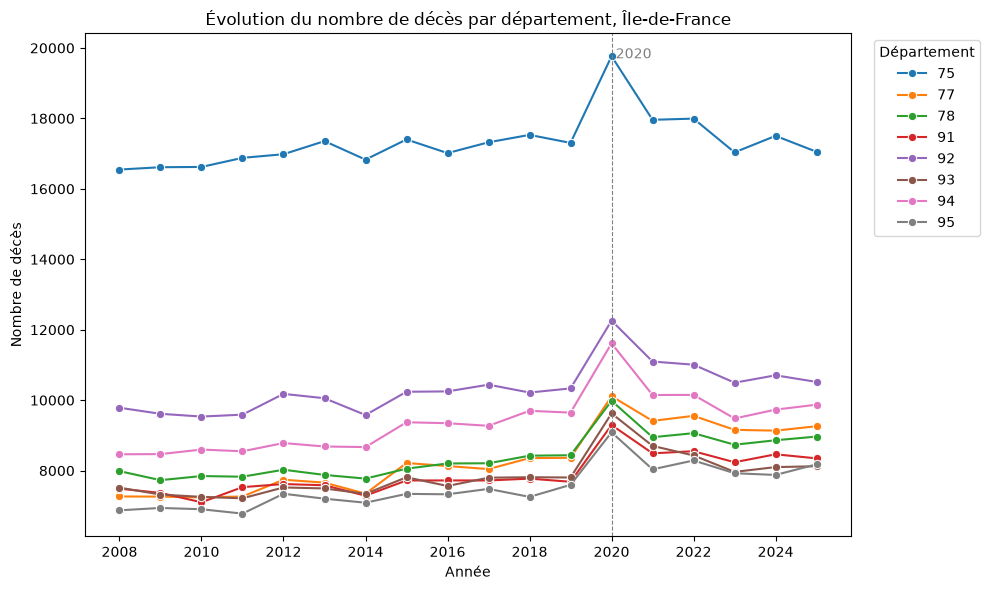

In [34]:
ordre = ["75", "77", "78", "91", "92", "93", "94", "95"]

# Total des décès par département et par année
par_dep = deces_fus.groupby("dep")[cols_deces].sum().loc[ordre]
par_dep.columns = [int(c[-4:]) for c in par_dep.columns] #renommer les années 

# Aide de Claude pour réaliser le graphique. 
# Format long pour seaborn
long = (par_dep.reset_index()
        .melt(id_vars="dep", var_name="annee", value_name="deces"))

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=long, x="annee", y="deces", hue="dep", hue_order=ordre,
             palette="tab10", marker="o", ax=ax)
ax.axvline(2020, color="grey", linestyle="--", linewidth=0.8)
ax.text(2020.1, ax.get_ylim()[1] * 0.98, "2020", color="grey", va="top")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de décès")
ax.set_title("Évolution du nombre de décès par département, Île-de-France")
ax.set_xticks(range(2008, 2026, 2))
ax.legend(title="Département", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Nous observons bien plusieurs éléments mentionnés précemment : 
- l'effet population : certains départements sont beaucoup plus peuplés et ont donc plus de morts 
- l'effet Covid : 2020 est une année de pic pour chaque département 

De plus, une certaine stabilité du nombre de décès se constate également. Des évolutions différentes peuvent tout de fois exister au sein même d'un département. 

# Taux de mortalité

Afin de calculer un indice de taux de mortalité : il faut également avoir en tête que chaque commune ne compte pas le même nombre d'habitants. Ainsi, étudier l'évolution de la mortalité passe par étudier l'évolution de la démographie. 

Pour cela, nous téléchargons des données concernant le nombre d'habitants. Un des fichiers les mieux renseignés est celui sur les populations municipales (donc par communes : la différence est très minime et repose sur l'inclusion des personnes ayant plusieurs lieux de résidence). 

In [35]:
url_pop = f"https://www.data.gouv.fr/api/1/datasets/r/27361ae9-dcab-4312-97a1-48dab5f39218"
r = requests.get(url_pop)

In [36]:
z = zipfile.ZipFile(io.BytesIO(r.content))
print(z.namelist())   # les fichiers du zip

['DS_POPULATIONS_HISTORIQUES_metadata.csv', 'DS_POPULATIONS_HISTORIQUES_data.csv']


In [37]:
#le fichier que nous souhaitons avoir est celui qui ne contient pas les metadata
fichier_data_pop = [n for n in z.namelist() if "metadata" not in n][0]

#on ouvre le zip
with z.open(fichier_data_pop) as f:
    pop = pd.read_csv(f, sep=";", dtype=str)

print(pop.shape)
print(pop.columns.tolist())
pop.head()

(813234, 6)
['FREQ', 'GEO', 'GEO_OBJECT', 'POPREF_MEASURE', 'TIME_PERIOD', 'OBS_VALUE']


,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040


In [38]:
pop.info()

<class 'pandas.DataFrame'>
RangeIndex: 813234 entries, 0 to 813233
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   FREQ            813234 non-null  str  
 1   GEO             813234 non-null  str  
 2   GEO_OBJECT      813234 non-null  str  
 3   POPREF_MEASURE  813234 non-null  str  
 4   TIME_PERIOD     813234 non-null  str  
 5   OBS_VALUE       813234 non-null  str  
dtypes: str(6)
memory usage: 52.9 MB


Le nombre très élévé de ligne est du au fait que plusieurs types d'objects géographiques sont observés : les régions, les départements, les communes, les arrondissements. Nous allons conserver les geo_object étant des communes, soit COM, et ensuite se concentrer sur l'Île de France. 
Mais tout d'abord, il est possible d'observer dès les premières lignes que le tableau est dans un format particulier : en effet, une ligne correspond à une année observée. La même commune est donc présente plusieurs fois. 

Nous modifions le format du tableau afin d'obtenir une commune = une ligne. 

Pour cela, nous gardons GEO_OBJECT = COM, les communes, et une mesure par population municipale, POPREF_MEASURE = PMUN.

Après avoir effectuer ce filtrage une première fois, nous avons réalisé que la commune de Paris était comptée comme une seule et unique commune. Les arrondissements sont renseignés mais sous le type ARM. Nous conservons donc aussi ARM, et au moment de la création des départements cela devrait bien nous permettre de ne garder que les arrondissements parisiens. 

In [39]:
pop["GEO_OBJECT"].value_counts()

GEO_OBJECT
COM       801734
ARR         7659
DEP         2300
ARM         1104
REG          391
FRANCE        46
Name: count, dtype: int64

In [40]:
pop_com = pop[(pop["POPREF_MEASURE"] == "PMUN") & (pop["GEO_OBJECT"].isin(["COM", "ARM"]))].copy()
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040
...,...,...,...,...,...,...
813229,A,16193,COM,PMUN,2015,1016
813230,A,15262,COM,PMUN,2014,534
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [41]:
pop_com["TIME_PERIOD"] = pop_com["TIME_PERIOD"].astype(int)
pop_com["OBS_VALUE"] = pd.to_numeric(pop_com["OBS_VALUE"], errors="coerce")

# on ne garde que la période utile par rapport aux données sur la mortalité 
pop_com = pop_com[pop_com["TIME_PERIOD"] >= 2008]

#on tourne le dataframe
pop_wide = pop_com.pivot(index="GEO", columns="TIME_PERIOD", values="OBS_VALUE")
pop_wide.columns = [f"pop_{annee}" for annee in pop_wide.columns]
pop_wide = pop_wide.reset_index().rename(columns={"GEO": "code_commune"})

pop_wide.head()

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023
0,01001,791,787,784,780,777,767,767,767,767,776,771,779,806,832,859,860
1,01002,194,207,221,234,235,236,239,241,243,248,253,256,262,267,273,270
2,01004,12792,13350,13835,13839,14233,14359,14022,14127,14081,14035,14204,14134,14288,14854,15554,15934
3,01005,1567,1592,1616,1600,1642,1635,1627,1619,1671,1689,1720,1751,1782,1897,1917,1906
4,01006,123,120,116,112,110,108,109,109,110,111,112,112,113,113,114,115


In [42]:
pop_wide.shape

(34906, 17)

In [43]:
pop_wide['dep'] = pop_wide['code_commune'].str[:2]
pop_idf = pop_wide[pop_wide["dep"].isin(dep_idf)].copy()
pop_idf["dep"].value_counts().sort_index()


dep
75     22
77    507
78    259
91    194
92     36
93     39
94     47
95    183
Name: count, dtype: int64

Pour Paris, il nous faut 20 arrondissements. Une valeur en trop est celle de la population totale de la ville de Paris, mais il semblerait y avoir encore une autre ligne supplémentaire. Observons. 

In [44]:
pop_test = pop_idf[pop_idf['dep']=="75"]
pop_test

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
29221,75056,2211297,2234105,2243833,2249975,2240621,2229621,2220445,2206488,2190327,2187526,2175601,2165423,2145906,2133111,2113705,2103778,75
29222,75101,17440,17614,17308,17443,17100,17022,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114,75
29223,75102,21793,22400,23009,22927,22390,21741,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847,75
29224,75103,34824,35655,35652,36120,35991,35666,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179,75
29225,75104,27977,28192,28012,27887,27769,27335,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332,75
29226,75105,62143,61531,60938,60800,60179,60273,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252,75
29227,75106,44322,43143,43451,43880,43224,43479,43134,42428,40916,41100,40525,40303,39625,40209,40432,40389,75
29228,75107,57082,57442,57974,57786,57092,56325,55486,54133,52512,51367,50196,48888,48520,47947,48196,48015,75
29229,75108,38702,40278,41280,40589,38749,39175,38257,36694,36453,36808,36222,35655,35631,35123,35418,35317,75
29230,75109,59157,60275,60139,60120,59474,59427,59389,59408,59629,59555,59835,60026,60168,58951,58419,57271,75


Il y a en effet le 75056 qui correspond au code de Paris, mais aussi un 751XX. Noous retirons ces deux lignes 

In [45]:
pop_fus = pop_idf[~pop_idf["code_commune"].isin(["75056", "751XX"])].copy()
pop_fus[pop_fus['dep'] == "75"]

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
29222,75101,17440,17614,17308,17443,17100,17022,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114,75
29223,75102,21793,22400,23009,22927,22390,21741,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847,75
29224,75103,34824,35655,35652,36120,35991,35666,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179,75
29225,75104,27977,28192,28012,27887,27769,27335,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332,75
29226,75105,62143,61531,60938,60800,60179,60273,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252,75
29227,75106,44322,43143,43451,43880,43224,43479,43134,42428,40916,41100,40525,40303,39625,40209,40432,40389,75
29228,75107,57082,57442,57974,57786,57092,56325,55486,54133,52512,51367,50196,48888,48520,47947,48196,48015,75
29229,75108,38702,40278,41280,40589,38749,39175,38257,36694,36453,36808,36222,35655,35631,35123,35418,35317,75
29230,75109,59157,60275,60139,60120,59474,59427,59389,59408,59629,59555,59835,60026,60168,58951,58419,57271,75
29231,75110,94321,95911,95394,94027,94474,92494,92228,91770,91932,90372,88557,86472,83459,83543,81926,83873,75


In [46]:
pop_fus["dep"].value_counts().sort_index()

dep
75     20
77    507
78    259
91    194
92     36
93     39
94     47
95    183
Name: count, dtype: int64

A présent, nous avons la population par commune de l'Île de France. 
Voyons si les communes correspondent avec celles liées aux décès. 

In [47]:
cols_deces = [f"deces_{a}" for a in range(2008, 2026)]
cols_pop = [f"pop_{a}" for a in range(2008, 2024)]

# Garder seulement les colonnes utiles, pour ne pas traîner les colonnes dérivées
d = deces_fus[["code_commune"] + cols_deces]
p = pop_fus[["code_commune"] + cols_pop]

check = d.merge(p, on="code_commune", how="outer", indicator=True)
print(check["_merge"].value_counts())

print("Seulement dans décès :", sorted(check.loc[check["_merge"] == "left_only", "code_commune"]))
print("Seulement dans pop   :", sorted(check.loc[check["_merge"] == "right_only", "code_commune"]))

_merge
both          1280
right_only       5
left_only        1
Name: count, dtype: int64
Seulement dans décès : ['93350']
Seulement dans pop   : ['77532', '91075', '91145', '91526', '95144']


Il y a ainsi 6 communes qui ne feront pas parties du dataframe mergés: Le Bourget (93), Vulaines-lès-Provins (77) , Bois-Herpin, Chatignonville et Roinvilliers (91), Châtenay-en-France (95). 

Nous pouvons maintenant créer une base mergée afin de calculer le taux de mortalité. 

In [48]:
base = d.merge(p, on="code_commune", how="inner", validate="one_to_one")
print(len(base), "communes dans la base")

print("NaN décès :", base[cols_deces].isna().sum().sum())
print("NaN pop   :", base[cols_pop].isna().sum().sum())
print("Communes avec une population à 0 ou manquante :",
      ((base[cols_pop] == 0) | base[cols_pop].isna()).any(axis=1).sum())

base

1280 communes dans la base
NaN décès : 0
NaN pop   : 0
Communes avec une population à 0 ou manquante : 0


,code_commune,deces_2008,deces_2009,deces_2010,deces_2011,deces_2012,deces_2013,deces_2014,deces_2015,deces_2016,...,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023
0,75101,39,40,44,45,33,35,27,37,40,...,16717,16545,16252,16266,16093,15917,16030,15919,15475,15114
1,75102,40,40,38,32,30,32,18,29,21,...,21263,20796,20260,20900,21420,21595,21130,21119,20433,19847
2,75103,55,49,52,52,69,46,52,58,58,...,35077,35049,34788,34115,34020,34025,33402,32793,32772,32179
3,75104,282,312,283,277,259,133,55,42,40,...,26796,27146,27487,28088,28763,29131,29064,28324,28039,27332
4,75105,544,560,603,646,680,709,675,478,366,...,60030,59333,59108,58850,58379,58227,57380,56841,55925,55252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1275,95676,0,0,2,2,1,0,0,0,0,...,503,508,506,503,497,490,490,489,487,498
1276,95678,1,3,1,2,1,4,1,2,3,...,838,851,863,859,861,861,857,852,848,858
1277,95680,456,419,382,259,355,273,243,258,120,...,27571,27564,27247,27676,28041,28423,28636,28836,29238,30053
1278,95682,0,0,0,0,0,0,0,0,1,...,177,179,183,185,187,189,193,196,198,205


Nous calculons à partir de base le taux de mortalité de chaque ville pour chaque année que nous stockons dans un nouveau dataset appelé taux. Il s'agit ici du taux de mortalité pour 1000 habitants.

In [58]:
annees = range(2008, 2024)   # la population s'arrête en 2023

taux = pd.concat(
    [base[["code_commune"]]]
    + [(base[f"deces_{a}"] / base[f"pop_{a}"] * 1000).rename(f"taux_{a}") for a in annees],
    axis=1)

taux["dep"] = taux["code_commune"].str[:2]
taux.head()

,code_commune,taux_2008,taux_2009,taux_2010,taux_2011,taux_2012,taux_2013,taux_2014,taux_2015,taux_2016,taux_2017,taux_2018,taux_2019,taux_2020,taux_2021,taux_2022,taux_2023,dep
0,75101,2.236239,2.270921,2.542177,2.579831,1.929825,2.056163,1.615122,2.236325,2.461236,2.459117,2.112720,1.570648,2.495321,2.512721,1.873990,2.778881,75
1,75102,1.835452,1.785714,1.651528,1.395734,1.339884,1.471873,0.846541,1.394499,1.036525,1.291866,1.400560,1.296596,1.183152,1.325820,1.125630,1.310022,75
2,75103,1.579371,1.374281,1.458544,1.439646,1.917146,1.289744,1.482453,1.654826,1.667242,1.260443,1.263962,1.322557,1.916053,1.890647,1.403637,1.553808,75
3,75104,10.079708,11.066969,10.102813,9.932944,9.326947,4.865557,2.052545,1.547189,1.455233,1.851324,2.051246,1.922351,1.651528,1.588759,1.640572,2.378165,75
4,75105,8.754003,9.101104,9.895303,10.625000,11.299623,11.763144,11.244378,8.056225,6.192055,5.556500,6.526319,6.199873,6.709655,5.594553,4.649084,4.814305,75


Afin de réaliser quelques statistiques descriptives sur ces taux, nous calculons le taux moyen en additionnant les décès et la population pour chaque ville. Ce taux moyen est un taux PAR VILLE. En faire la moyenne donne donc la moyenne des taux mais pas un taux en Île de France.

In [65]:
cols_d = [f"deces_{a}" for a in annees]
cols_p = [f"pop_{a}" for a in annees]

taux["taux_moyen"] = base[cols_d].sum(axis=1) / base[cols_p].sum(axis=1) * 1000

In [70]:
taux["taux_moyen"].describe()

count    1280.000000
mean        4.868478
std        26.411777
min         0.000000
25%         1.285001
50%         1.782171
75%         2.930144
max       852.441715
Name: taux_moyen, dtype: float64

Nous remarquons que la moyenne des taux moyens de chaque ville entre 2008 et 2023 est de 4,86, avec une médiane de 1,285. La proportion de petites villes doit être importante car la moyenne est plus élevée que la médiane : les petites villes où les gens ne meurent pas sont nombreuses mais la moyenne est biaisée par les villes avec un très grand taux. 

On remarque par ailleurs que certaines communes ont un taux minimum de 0, il peut s'agir des petites communes n'ayant aucun pôle de santé, tandis que d'autres peuvent avoir des taux totalement aberrants, comme 850 : sûrement les gros centres hopistaliers. 

Voyons cela de plus près. 

Commençons par regarder quelles sont les villes avec un taux presque nul.

In [68]:
taux.sort_values("taux_moyen", ascending=False).tail(10)[["code_commune", "taux_moyen"]]

,code_commune,taux_moyen
721,78505,0.303628
948,91602,0.295814
884,91374,0.277855
319,77313,0.263505
857,91247,0.249035
844,91204,0.242503
493,77498,0.215332
916,91495,0.195695
757,78606,0.000000
213,77205,0.000000


In [82]:
obs3 = deces_idf[(deces_idf["code_commune"] == '77205') | (deces_idf["code_commune"] == '78606')]
obs3[["code_commune", "deces_2016", "deces_2017", 'deces_2018', 'deces_2019', 'deces_2020', 'deces_2021', 'deces_2022', "deces_2023", "deces_2024", "deces_2025"]]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
36271,77205,0,0,0,0,0,0,0,0,1,0
36446,78606,0,0,0,0,0,0,0,0,1,0


Gesvres-le-Chapitre (145 habitants en 2026) et Tartre-Gaudran (73 habitants en 2023) sont les deux communes avec le taux le plus petit : elles ont respectivement un seul décès enregistrés sur la période. C'est encore une fois lié à ce que nous mentionnons plus tôt. 

Enfin, pour les taux les plus élévés :

In [69]:
taux.sort_values("taux_moyen", ascending=False).head(10)[["code_commune", "taux_moyen"]]

,code_commune,taux_moyen
244,77237,852.441715
189,77180,271.943574
855,91243,190.322093
826,91135,102.131400
605,78227,87.144228
486,77489,76.633892
795,91044,61.080080
720,78502,58.398128
640,78310,56.539920
627,78281,46.350292


La première ville est Jossigny, qui héberge le Grand Hôpital de l'Est Francilien. Cela semble donc cohérent avec notre hypothèse. Après vérification, les 10 communes présentes ici ont toutes au moins un établissement spécialisé, privé ou de proximité, sauf 3 : Fontenay-lès-Briis (91243), Évecquemont (78227), Vaux-sur-Lunain (77489) et Goussonville (78281), qui sont de petits village. 

Voyons les décès associés : 

In [ ]:
obs5 = deces_idf[(deces_idf["code_commune"] == '91243') | (deces_idf["code_commune"] == '77489') | (deces_idf["code_commune"] == '78281')]

,code_commune,deces_2016,deces_2017,deces_2018,deces_2019,deces_2020,deces_2021,deces_2022,deces_2023,deces_2024,deces_2025
329,91243,398,421,411,368,387,305,307,303,193,99
2589,78281,36,23,23,21,43,46,28,16,16,14
4095,77489,17,9,15,21,22,20,10,21,24,15


In [85]:
obs6 = pop_fus[(pop_fus["code_commune"] == '91243') | (pop_fus["code_commune"] == '77489') | (pop_fus["code_commune"] == '78281')]
obs6

,code_commune,pop_2008,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021,pop_2022,pop_2023,dep
30416,77489,196,197,200,203,206,204,204,211,219,226,228,232,237,234,232,229,77
30558,78281,600,611,617,615,614,613,614,615,618,622,625,625,628,636,643,650,78
34367,91243,1782,1832,1882,1881,1882,1921,1972,2022,2076,2149,2184,2232,2281,2297,2322,2350,91


Ce sont en effet de petites villes, avec un nombre de décès élevé proportionnellement à leur population. Si elles n'ont pas de centres de santé, cela peut aussi être que la population y est très vieillissante et décède chez elle. 

En calculant maintenant un taux sur l'Île de France et non plus par ville, on retrouve les chiffres officiels. En 2025 en Île-de-France, le taux standardisé est d'environ 6,7. Nous sommes donc plutôt proche de ce taux mais sur une période beaucoup plus large. Le pic de 2020 est aussi observable : 

In [71]:
reg = base[cols_d].sum().values / base[cols_p].sum().values * 1000
pd.Series(reg, index=range(2008, 2024)).round(2)

2008    6.17
2009    6.08
2010    6.03
2011    6.04
2012    6.24
2013    6.18
2014    5.98
2015    6.30
2016    6.24
2017    6.27
2018    6.31
2019    6.29
2020    7.48
2021    6.72
2022    6.71
2023    6.34
dtype: float64

taux mortalité 
qq stat 
repres graphique 